In [ ]:
!pip install lightkurve pandas scikit-learn torch


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 27.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 30.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 92.2 MB/s  0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=f339ba3884586066bdc6aca188be251de2e5a9ad4da70446901a97010e450c6f
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=cf6a8e2df6407a3511dae4e43162856a2c4726e1ce1b170d32b7ea8739d75469
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a897019

In [ ]:
import pandas as pd
tce = pd.read_csv("q1_q17_dr24_tce.csv", comment="#")
print(tce.shape)
print(tce.av_training_set.value_counts())

(20367, 26)


AttributeError: 'DataFrame' object has no attribute 'av_training_set'

In [ ]:
import pandas as pd
tce = pd.read_csv("q1_q17_dr24_tce.csv", comment="#")
print(tce.shape)
print(tce.av_training_set.value_counts())


(20367, 26)


AttributeError: 'DataFrame' object has no attribute 'av_training_set'

In [ ]:
print(list(tce.columns))

['kepid', 'tce_plnt_num', 'tce_rogue_flag', 'tce_period', 'tce_period_err', 'tce_time0bk', 'tce_time0bk_err', 'tce_impact', 'tce_impact_err', 'tce_duration', 'tce_duration_err', 'tce_depth', 'tce_depth_err', 'tce_model_snr', 'tce_prad', 'tce_prad_err', 'tce_eqt', 'tce_eqt_err', 'tce_insol', 'tce_insol_err', 'tce_steff', 'tce_steff_err', 'tce_slogg', 'tce_slogg_err', 'tce_sradius', 'tce_sradius_err']


In [ ]:
import pandas as pd
tce = pd.read_csv("q1_q17_dr24_tce.csv", comment="#")
print(tce.shape)
print(tce.av_training_set.value_counts())

(8931, 26)


AttributeError: 'DataFrame' object has no attribute 'av_training_set'

In [ ]:
import pandas as pd
tce = pd.read_csv("q1_q17_dr24_tce.csv", comment="#")
print(tce.shape)
print(tce.av_training_set.value_counts())


(11436, 9)


AttributeError: 'DataFrame' object has no attribute 'av_training_set'

In [ ]:
print(tce.shape)
print(list(tce.columns))


(11436, 9)
['00e+02', 'Unnamed: 1', 'Unnamed: 2', '8321.00', '347.00', '3.76', '0.28', '3.118', '1.049']


In [ ]:
import pandas as pd
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+*+from+q1_q17_dr24_tce&format=csv"
tce = pd.read_csv(url)
tce.to_csv("tce_full.csv", index=False)
print(tce.shape)
print(tce.av_training_set.value_counts())

(20367, 158)
av_training_set
AFP    9596
UNK    4630
PC     3600
NTP    2541
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# sirf PC, AFP, NTP rakho (UNK hata do)
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()

# PC = planet (1), baaki = not planet (0)
tce["planet"] = (tce.av_training_set == "PC").astype(int)

# star ke hisaab se split (ek star ke signals ek hi side mein rahein)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(tce, groups=tce.kepid))

train = tce.iloc[train_idx]
test = tce.iloc[test_idx]
print("train:", len(train), "test:", len(test))
print("test mein planets:", test.planet.sum())

train: 14193 test: 1544
test mein planets: 359


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

feats = ["tce_period", "tce_duration", "tce_depth"]

base = HistGradientBoostingClassifier(random_state=42)
base.fit(train[feats], train.planet)

probs = base.predict_proba(test[feats])[:, 1]
print("baseline AUC:", roc_auc_score(test.planet, probs))

baseline AUC: 0.9389560781824806


In [ ]:
import lightkurve as lk
import numpy as np

def load_lc(kepid):
    search = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
    return search.download_all().stitch().remove_nans()

# sirf 1 star pe test karo
kepid = int(train.kepid.iloc[0])
lc = load_lc(kepid)
print("star:", kepid)
print("data points:", len(lc.time))

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


star: 1162345
data points: 65264


In [ ]:
def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
    flat = lc.flatten(window_length=401, mask=mask)
    t, f = flat.time.value, flat.flux.value
    phase = (t - t0 + period / 2) % period - period / 2
    glob = binned(phase, f, -period / 2, period / 2, 2001)
    loc = binned(phase, f, -4 * dur, 4 * dur, 201)
    norm = lambda v: (v - np.median(v)) / abs((v - np.median(v)).min())
    return norm(glob), norm(loc)

row = train[train.kepid == kepid].iloc[0]
g, l = make_views(lc, row.tce_period, row.tce_time0bk, row.tce_duration)
print("global:", g.shape, "local:", l.shape)

global: (2001,) local: (201,)


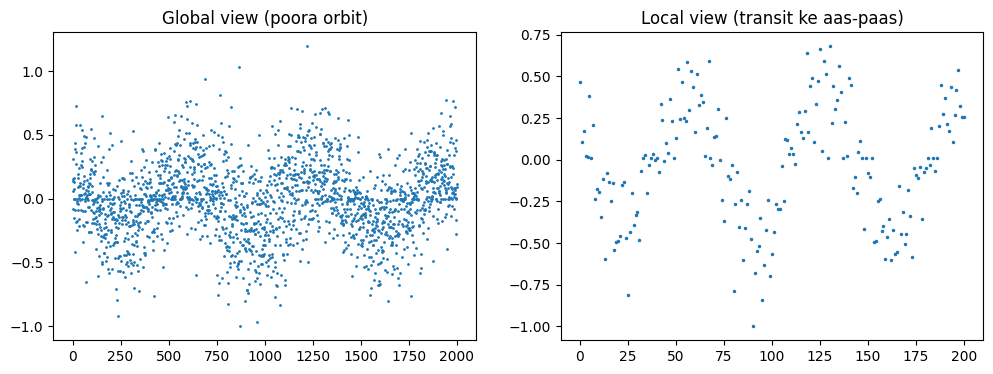

label: AFP


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(g, ".", markersize=2)
ax[0].set_title("Global view (poora orbit)")
ax[1].plot(l, ".", markersize=3)
ax[1].set_title("Local view (transit ke aas-paas)")
plt.show()

print("label:", row.av_training_set)

In [ ]:
import os, pickle, time

os.makedirs("cache", exist_ok=True)

def build_row(r):
    path = f"cache/{int(r.kepid)}_{int(r.tce_plnt_num)}.pkl"
    if os.path.exists(path):
        return pickle.load(open(path, "rb"))
    try:
        lc = load_lc(int(r.kepid))
        g, l = make_views(lc, r.tce_period, r.tce_time0bk, r.tce_duration)
        out = (g, l, r.planet)
        pickle.dump(out, open(path, "wb"))
        return out
    except Exception as e:
        print("skip", int(r.kepid), str(e)[:60])
        return None

sample = train.sample(20, random_state=1)
data = []
start = time.time()
for _, r in sample.iterrows():
    out = build_row(r)
    if out is not None:
        data.append(out)
print("done:", len(data), "rows in", round(time.time() - start), "seconds")

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_2742/3363137913.py", line 23, in <cell line: 0>
    out = build_row(r)
  File "/tmp/ipykernel_2742/3363137913.py", line 10, in build_row
    lc = load_lc(int(r.kepid))
  File "/tmp/ipykernel_2742/49038683.py", line 6, in load_lc
    return search.download_all().stitch().remove_nans()
           ~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/lightkurve/utils.py", line 568, in wrapper
    return f(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/lightkurve/search.py", line 501, in download_all
    self._download_one(
    ~~~~~~~~~~~~~~~~~~^
        table=self.table[idx : idx + 1],
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<3 lines>...
        **kwargs,
        ^^^^^^^^^
    )


TypeError: object of type 'NoneType' has no len()

In [ ]:
print(len(os.listdir("cache")), "stars saved")

16 stars saved


In [ ]:
sample = train.sample(80, random_state=1)
data = []
start = time.time()
for _, r in sample.iterrows():
    out = build_row(r)
    if out is not None:
        data.append(out)
print("done:", len(data), "rows in", round(time.time() - start), "seconds"
)

skip 9071593 Error in reading Data product /root/.lightkurve/cache/mastDo
done: 79 rows in 1 seconds


In [ ]:
print(len(data), "rows")
print("planets:", sum(d[2] for d in data), "not planets:", len(data) - sum(d[2] for d in data))

79 rows
planets: 22 not planets: 57


In [ ]:
import torch, torch.nn as nn

G = torch.tensor(np.stack([d[0] for d in data]), dtype=torch.float32).unsqueeze(1)
L = torch.tensor(np.stack([d[1] for d in data]), dtype=torch.float32).unsqueeze(1)
Y = torch.tensor([d[2] for d in data], dtype=torch.float32)

def branch(n_in):
    return nn.Sequential(
        nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.AdaptiveAvgPool1d(8), nn.Flatten())

class Net(nn.Module):
    def _init_(self):
        super()._init_()
        self.g = branch(2001)
        self.l = branch(201)
        self.fc = nn.Sequential(nn.Linear(512, 64), nn.ReLU(),
                                nn.Dropout(0.3), nn.Linear(64, 1))
    def forward(self, g, l):
        return self.fc(torch.cat([self.g(g), self.l(l)], dim=1)).squeeze(1)

torch.manual_seed(42)
model = Net()
print(G.shape, L.shape, Y.shape)
print

torch.Size([79, 1, 2001]) torch.Size([79, 1, 201]) torch.Size([79])


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(30):
    model.train()
    opt.zero_grad()
    loss = loss_fn(model(G, L), Y)
    loss.backward()
    opt.step()
    if epoch % 5 == 0:
        print("epoch", epoch, "loss", round(loss.item(), 4))

ValueError: optimizer got an empty parameter list

In [ ]:
import torch, torch.nn as nn

G = torch.tensor(np.stack([d[0] for d in data]), dtype=torch.float32).unsqueeze(1)
L = torch.tensor(np.stack([d[1] for d in data]), dtype=torch.float32).unsqueeze(1)
Y = torch.tensor([d[2] for d in data], dtype=torch.float32)

def branch(n_in):
    return nn.Sequential(
        nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.AdaptiveAvgPool1d(8), nn.Flatten())

class Net(nn.Module):
    def _init_(self):
        super()._init_()
        self.g = branch(2001)
        self.l = branch(201)
        self.fc = nn.Sequential(nn.Linear(512, 64), nn.ReLU(),
                                nn.Dropout(0.3), nn.Linear(64, 1))
    def forward(self, g, l):
        return self.fc(torch.cat([self.g(g), self.l(l)], dim=1)).squeeze(1)

torch.manual_seed(42)
model = Net()
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 0


In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(30):
    model.train()
    opt.zero_grad()
    loss = loss_fn(model(G, L), Y)
    loss.backward()
    opt.step()
    if epoch % 5 == 0:
        print("epoch", epoch, "loss", round(loss.item(), 4))

ValueError: optimizer got an empty parameter list

In [ ]:
import torch, torch.nn as nn

G = torch.tensor(np.stack([d[0] for d in data]), dtype=torch.float32).unsqueeze(1)
L = torch.tensor(np.stack([d[1] for d in data]), dtype=torch.float32).unsqueeze(1)
Y = torch.tensor([d[2] for d in data], dtype=torch.float32)

def branch():
    return nn.Sequential(
        nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.AdaptiveAvgPool1d(8), nn.Flatten())

class Net(nn.Module):
    def _init_(self):
        super()._init_()
        self.g = branch()
        self.l = branch()
        self.fc = nn.Sequential(nn.Linear(512, 64), nn.ReLU(),
                                nn.Dropout(0.3), nn.Linear(64, 1))
    def forward(self, g, l):
        return self.fc(torch.cat([self.g(g), self.l(l)], dim=1)).squeeze(1)

torch.manual_seed(42)
net = Net()
print("parameters:", sum(p.numel() for p in net.parameters()))

loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

for epoch in range(30):
    net.train()
    opt.zero_grad()
    loss = loss_fn(net(G, L), Y)
    loss.backward()
    opt.step()
    if epoch % 5 == 0:
        print("epoch", epoch, "loss", round(loss.item(), 4))

parameters: 0


ValueError: optimizer got an empty parameter list

In [ ]:
import os, pickle, numpy as np, torch, torch.nn as nn

print("test, 6 aana chahiye:", sum(p.numel() for p in nn.Linear(2, 2).parameters()))

data = [pickle.load(open("cache/" + f, "rb")) for f in os.listdir("cache")]
print(len(data), "rows")

G = torch.tensor(np.stack([d[0] for d in data]), dtype=torch.float32).unsqueeze(1)
L = torch.tensor(np.stack([d[1] for d in data]), dtype=torch.float32).unsqueeze(1)
Y = torch.tensor([float(d[2]) for d in data], dtype=torch.float32)

def branch():
    return nn.Sequential(
        nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.AdaptiveAvgPool1d(8), nn.Flatten())

class Net(nn.Module):
    def _init_(self):
        super()._init_()
        self.g = branch()
        self.l = branch()
        self.fc = nn.Sequential(nn.Linear(512, 64), nn.ReLU(),
                                nn.Dropout(0.3), nn.Linear(64, 1))
    def forward(self, g, l):
        return self.fc(torch.cat([self.g(g), self.l(l)], dim=1)).squeeze(1)

torch.manual_seed(42)
net = Net()
print("parameters:", sum(p.numel() for p in net.parameters()))

loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
for epoch in range(30):
    net.train()
    opt.zero_grad()
    loss = loss_fn(net(G, L), Y)
    loss.backward()
    opt.step()
    if epoch % 5 == 0:
        print("epoch", epoch, "loss", round(loss.item(), 4))

test, 6 aana chahiye: 6
79 rows
parameters: 0


ValueError: optimizer got an empty parameter list

In [ ]:
import torch.nn as nn
m = nn.Sequential(nn.Conv1d(1, 16, 5), nn.Linear(4, 2))
print("m parameters:", sum(p.numel() for p in m.parameters()))

m parameters: 106


In [ ]:
import os, pickle, numpy as np, torch, torch.nn as nn

data = [pickle.load(open("cache/" + f, "rb")) for f in os.listdir("cache")]
G = torch.tensor(np.stack([d[0] for d in data]), dtype=torch.float32).unsqueeze(1)
L = torch.tensor(np.stack([d[1] for d in data]), dtype=torch.float32).unsqueeze(1)
Y = torch.tensor([float(d[2]) for d in data], dtype=torch.float32)

def branch():
    return nn.Sequential(
        nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.AdaptiveAvgPool1d(8), nn.Flatten())

g_branch, l_branch = branch(), branch()
head = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1))
all_layers = nn.ModuleList([g_branch, l_branch, head])

def net(g, l):
    return head(torch.cat([g_branch(g), l_branch(l)], dim=1)).squeeze(1)

torch.manual_seed(42)
print(len(data), "rows")
print("parameters:", sum(p.numel() for p in all_layers.parameters()))

loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(all_layers.parameters(), lr=1e-3)
for epoch in range(30):
    all_layers.train()
    opt.zero_grad()
    loss = loss_fn(net(G, L), Y)
    loss.backward()
    opt.step()
    if epoch % 5 == 0:
        print("epoch", epoch, "loss", round(loss.item(), 4))

79 rows
parameters: 38273
epoch 0 loss 0.6949
epoch 5 loss 0.6356
epoch 10 loss 0.5872
epoch 15 loss 0.5889
epoch 20 loss 0.5566
epoch 25 loss 0.5435


In [ ]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

tce = pd.read_csv("tce_full.csv")
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)

gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
train = tce.iloc[train_idx]
test = tce.iloc[test_idx]
print("train:", len(train), "test:", len(test))

train: 14193 test: 1544


In [ ]:
import lightkurve as lk
import numpy as np, os, pickle, time

def load_lc(kepid):
    search = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
    return search.download_all().stitch().remove_nans()

def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
    flat = lc.flatten(window_length=401, mask=mask)
    t, f = flat.time.value, flat.flux.value
    phase = (t - t0 + period / 2) % period - period / 2
    glob = binned(phase, f, -period / 2, period / 2, 2001)
    loc = binned(phase, f, -4 * dur, 4 * dur, 201)
    norm = lambda v: (v - np.median(v)) / abs((v - np.median(v)).min())
    return norm(glob), norm(loc)

def build_row(r):
    path = f"cache/{int(r.kepid)}_{int(r.tce_plnt_num)}.pkl"
    if os.path.exists(path):
        return pickle.load(open(path, "rb"))
    try:
        lc = load_lc(int(r.kepid))
        g, l = make_views(lc, r.tce_period, r.tce_time0bk, r.tce_duration)
        out = (g, l, r.planet)
        pickle.dump(out, open(path, "wb"))
        return out
    except Exception as e:
        print("skip", int(r.kepid), str(e)[:60])
        return None

os.makedirs("cache_test", exist_ok=True)
print("functions ready")

functions ready


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [ ]:
def build_test_row(r):
    path = f"cache_test/{int(r.kepid)}_{int(r.tce_plnt_num)}.pkl"
    if os.path.exists(path):
        return pickle.load(open(path, "rb"))
    try:
        lc = load_lc(int(r.kepid))
        g, l = make_views(lc, r.tce_period, r.tce_time0bk, r.tce_duration)
        out = (g, l, r.planet)
        pickle.dump(out, open(path, "wb"))
        return out
    except Exception as e:
        print("skip", int(r.kepid), str(e)[:60])
        return None

test_sample = test.sample(40, random_state=1)
test_data = []
start = time.time()
for _, r in test_sample.iterrows():
    out = build_test_row(r)
    if out is not None:
        test_data.append(out)
print("done:", len(test_data), "rows in", round(time.time() - start), "seconds")

done: 40 rows in 948 seconds


In [ ]:
from sklearn.metrics import roc_auc_score

Gt = torch.tensor(np.stack([d[0] for d in test_data]), dtype=torch.float32).unsqueeze(1)
Lt = torch.tensor(np.stack([d[1] for d in test_data]), dtype=torch.float32).unsqueeze(1)
Yt = np.array([float(d[2]) for d in test_data])

all_layers.eval()
with torch.no_grad():
    p = torch.sigmoid(net(Gt, Lt)).numpy()

print("test mein planets:", int(Yt.sum()), "of", len(Yt))
print("CNN AUC:", roc_auc_score(Yt, p))

test mein planets: 6 of 40
CNN AUC: 0.5735294117647058


In [ ]:
test40 = test_sample.copy()
base40 = base.predict_proba(test40[feats])[:, 1] if "base" in globals() else None
print("baseline on same 40:", roc_auc_score(test40.planet, base40) if base40 is not None else "base nahi mila")

baseline on same 40: base nahi mila


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

feats = ["tce_period", "tce_duration", "tce_depth"]
base = HistGradientBoostingClassifier(random_state=42)
base.fit(train[feats], train.planet)

print("baseline on full test:", roc_auc_score(test.planet, base.predict_proba(test[feats])[:, 1]))
print("baseline on same 40:", roc_auc_score(test_sample.planet, base.predict_proba(test_sample[feats])[:, 1]))

baseline on full test: 0.9389560781824806
baseline on same 40: 0.892156862745098


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/exoplanet
!cp tce_full.csv /content/drive/MyDrive/exoplanet/
!cp -r cache cache_test /content/drive/MyDrive/exoplanet/
print("saved")

Mounted at /content/drive
saved


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!pip install -q lightkurve
!cp -rn /content/drive/MyDrive/exoplanet/* /content/

import os, pickle, time, numpy as np, pandas as pd
import lightkurve as lk
import torch, torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

tce = pd.read_csv("tce_full.csv")
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
train, test = tce.iloc[train_idx], tce.iloc[test_idx]

def load_lc(kepid):
    s = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
    return s.download_all().stitch().remove_nans()

def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
    flat = lc.flatten(window_length=401, mask=mask)
    t, f = flat.time.value, flat.flux.value
    phase = (t - t0 + period / 2) % period - period / 2
    glob = binned(phase, f, -period / 2, period / 2, 2001)
    loc = binned(phase, f, -4 * dur, 4 * dur, 201)
    norm = lambda v: (v - np.median(v)) / abs((v - np.median(v)).min())
    return norm(glob), norm(loc)

def build_row(r, folder="cache"):
    os.makedirs(folder, exist_ok=True)
    path = f"{folder}/{int(r.kepid)}_{int(r.tce_plnt_num)}.pkl"
    if os.path.exists(path):
        return pickle.load(open(path, "rb"))
    try:
        lc = load_lc(int(r.kepid))
        g, l = make_views(lc, r.tce_period, r.tce_time0bk, r.tce_duration)
        out = (g, l, r.planet)
        pickle.dump(out, open(path, "wb"))
        return out
    except Exception as e:
        print("skip", int(r.kepid), str(e)[:60])
        return None

print("train:", len(train), "test:", len(test))
print("cache:", len(os.listdir("cache")), "cache_test:", len(os.listdir("cache_test")))

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


train: 14193 test: 1544
cache: 79 cache_test: 40


In [ ]:
train_sample = train.sample(300, random_state=1)
data = []
start = time.time()
for i, (_, r) in enumerate(train_sample.iterrows()):
    out = build_row(r)
    if out is not None:
        data.append(out)
    if i % 25 == 0:
        print(i, "done,", round((time.time() - start) / 60), "min")
        os.system("cp -r cache /content/drive/MyDrive/exoplanet/")
print("done:", len(data), "rows in", round((time.time() - start) / 60), "min")

NameError: name 'data' is not defined

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!pip install -q lightkurve
!cp -r --update=none /content/drive/MyDrive/exoplanet/* /content/

import os, pickle, time, numpy as np, pandas as pd
import lightkurve as lk
import torch, torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

tce = pd.read_csv("tce_full.csv")
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
train, test = tce.iloc[train_idx], tce.iloc[test_idx]

def load_lc(kepid):
    s = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
    return s.download_all().stitch().remove_nans()

def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
    flat = lc.flatten(window_length=401, mask=mask)
    t, f = flat.time.value, flat.flux.value
    phase = (t - t0 + period / 2) % period - period / 2
    glob = binned(phase, f, -period / 2, period / 2, 2001)
    loc = binned(phase, f, -4 * dur, 4 * dur, 201)
    norm = lambda v: (v - np.median(v)) / abs((v - np.median(v)).min())
    return norm(glob), norm(loc)

def build_row(r, folder="cache"):
    os.makedirs(folder, exist_ok=True)
    path = f"{folder}/{int(r.kepid)}_{int(r.tce_plnt_num)}.pkl"
    if os.path.exists(path):
        return pickle.load(open(path, "rb"))
    try:
        lc = load_lc(int(r.kepid))
        g, l = make_views(lc, r.tce_period, r.tce_time0bk, r.tce_duration)
        out = (g, l, r.planet)
        pickle.dump(out, open(path, "wb"))
        return out
    except Exception as e:
        print("skip", int(r.kepid), str(e)[:60])
        return None

print("train:", len(train), "test:", len(test))
print("cache:", len(os.listdir("cache")), "cache_test:", len(os.listdir("cache_test")))

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


train: 14193 test: 1544
cache: 79 cache_test: 40


In [ ]:
train_sample = train.sample(300, random_state=1)
data = []
start = time.time()
for i, (_, r) in enumerate(train_sample.iterrows()):
    out = build_row(r)
    if out is not None:
        data.append(out)
    if i % 25 == 0:
        print(i, "done,", round((time.time() - start) / 60), "min")
        os.system("cp -r cache /content/drive/MyDrive/exoplanet/")
print("done:", len(data), "rows in", round((time.time() - start) / 60), "min")

0 done, 0 min
25 done, 0 min
50 done, 0 min
75 done, 0 min
100 done, 7 min
125 done, 17 min
150 done, 27 min
175 done, 36 min
200 done, 45 min
225 done, 54 min
250 done, 64 min
275 done, 72 min
done: 300 rows in 80 min


In [ ]:
os.system("cp -r cache /content/drive/MyDrive/exoplanet/")
print("saved")

# train data
data = [pickle.load(open("cache/" + f, "rb")) for f in os.listdir("cache")]
G = torch.tensor(np.stack([d[0] for d in data]), dtype=torch.float32).unsqueeze(1)
L = torch.tensor(np.stack([d[1] for d in data]), dtype=torch.float32).unsqueeze(1)
Y = torch.tensor([float(d[2]) for d in data], dtype=torch.float32)

# test data (same 40 stars)
names = sorted(os.listdir("cache_test"))
test_data = [pickle.load(open("cache_test/" + f, "rb")) for f in names]
Gt = torch.tensor(np.stack([d[0] for d in test_data]), dtype=torch.float32).unsqueeze(1)
Lt = torch.tensor(np.stack([d[1] for d in test_data]), dtype=torch.float32).unsqueeze(1)
Yt = np.array([float(d[2]) for d in test_data])

# model
def branch():
    return nn.Sequential(
        nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.AdaptiveAvgPool1d(8), nn.Flatten())

torch.manual_seed(42)
g_branch, l_branch = branch(), branch()
head = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1))
all_layers = nn.ModuleList([g_branch, l_branch, head])

def net(g, l):
    return head(torch.cat([g_branch(g), l_branch(l)], dim=1)).squeeze(1)

loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(all_layers.parameters(), lr=1e-3)

for epoch in range(40):
    all_layers.train()
    perm = torch.randperm(len(Y))
    for i in range(0, len(Y), 32):
        b = perm[i:i + 32]
        opt.zero_grad()
        loss = loss_fn(net(G[b], L[b]), Y[b])
        loss.backward()
        opt.step()
    if epoch % 10 == 0:
        print("epoch", epoch, "loss", round(loss.item(), 4))

# score on the 40 test stars
all_layers.eval()
with torch.no_grad():
    p = torch.sigmoid(net(Gt, Lt)).numpy()

# baseline on the same 40
feats = ["tce_period", "tce_duration", "tce_depth"]
base = HistGradientBoostingClassifier(random_state=42).fit(train[feats], train.planet)
keys = [tuple(map(int, f[:-4].split("_"))) for f in names]
t40 = test.set_index(["kepid", "tce_plnt_num"]).loc[keys]

print("train rows:", len(data), "| planets:", int(Y.sum()))
print("test planets:", int(Yt.sum()), "of", len(Yt))
print("CNN AUC:", roc_auc_score(Yt, p))
print("baseline AUC (same 40):", roc_auc_score(t40.planet, base.predict_proba(t40[feats])[:, 1]))

saved
epoch 0 loss 0.5279
epoch 10 loss 0.5236
epoch 20 loss 0.4484
epoch 30 loss 0.2012
train rows: 300 | planets: 74
test planets: 6 of 40
CNN AUC: 0.946078431372549
baseline AUC (same 40): 0.892156862745098


In [ ]:
test_sample = test.sample(400, random_state=1)
test_data = []
start = time.time()
for i, (_, r) in enumerate(test_sample.iterrows()):
    out = build_row(r, folder="cache_test")
    if out is not None:
        test_data.append((out, r.kepid, r.tce_plnt_num))
    if i % 25 == 0:
        print(i, "done,", round((time.time() - start) / 60), "min")
        os.system("cp -r cache_test /content/drive/MyDrive/exoplanet/")
os.system("cp -r cache_test /content/drive/MyDrive/exoplanet/")
print("done:", len(test_data), "rows in", round((time.time() - start) / 60), "min")

0 done, 0 min
25 done, 0 min
50 done, 3 min
75 done, 13 min
100 done, 21 min
125 done, 29 min
150 done, 38 min
175 done, 45 min
200 done, 52 min
225 done, 59 min
250 done, 67 min
275 done, 75 min
300 done, 82 min
325 done, 90 min
350 done, 97 min
skip 2437112 Error in reading Data product /root/.lightkurve/cache/mastDo
375 done, 104 min
skip 5024252 Error in reading Data product /root/.lightkurve/cache/mastDo
done: 398 rows in 111 min


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!pip install -q lightkurve
!cp -r --update=none /content/drive/MyDrive/exoplanet/* /content/

import os, pickle, time, numpy as np, pandas as pd
import lightkurve as lk
import torch, torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

tce = pd.read_csv("tce_full.csv")
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
train, test = tce.iloc[train_idx], tce.iloc[test_idx]

print("train:", len(train), "test:", len(test))
print("cache:", len(os.listdir("cache")), "cache_test:", len(os.listdir("cache_test")))

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


train: 14193 test: 1544
cache: 300 cache_test: 398


In [ ]:
# train data (300 stars)
data = [pickle.load(open("cache/" + f, "rb")) for f in os.listdir("cache")]
G = torch.tensor(np.stack([d[0] for d in data]), dtype=torch.float32).unsqueeze(1)
L = torch.tensor(np.stack([d[1] for d in data]), dtype=torch.float32).unsqueeze(1)
Y = torch.tensor([float(d[2]) for d in data], dtype=torch.float32)

# test data (398 stars), keys filename se
names = sorted(os.listdir("cache_test"))
tdata = [pickle.load(open("cache_test/" + f, "rb")) for f in names]
Gt = torch.tensor(np.stack([d[0] for d in tdata]), dtype=torch.float32).unsqueeze(1)
Lt = torch.tensor(np.stack([d[1] for d in tdata]), dtype=torch.float32).unsqueeze(1)
Yt = np.array([float(d[2]) for d in tdata])
keys = [tuple(map(int, f[:-4].split("_"))) for f in names]

def branch():
    return nn.Sequential(
        nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.AdaptiveAvgPool1d(8), nn.Flatten())

torch.manual_seed(42)
g_branch, l_branch = branch(), branch()
head = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1))
all_layers = nn.ModuleList([g_branch, l_branch, head])

def net(g, l):
    return head(torch.cat([g_branch(g), l_branch(l)], dim=1)).squeeze(1)

loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(all_layers.parameters(), lr=1e-3)
for epoch in range(40):
    all_layers.train()
    perm = torch.randperm(len(Y))
    for i in range(0, len(Y), 32):
        b = perm[i:i + 32]
        opt.zero_grad()
        loss_fn(net(G[b], L[b]), Y[b]).backward()
        opt.step()

all_layers.eval()
with torch.no_grad():
    p = torch.sigmoid(net(Gt, Lt)).numpy()

feats = ["tce_period", "tce_duration", "tce_depth"]
base = HistGradientBoostingClassifier(random_state=42).fit(train[feats], train.planet)
t = test.set_index(["kepid", "tce_plnt_num"]).loc[keys]

print("train rows:", len(data), "| test rows:", len(Yt), "| test planets:", int(Yt.sum()))
print("CNN AUC:", roc_auc_score(Yt, p))
print("baseline AUC (same test stars):", roc_auc_score(t.planet, base.predict_proba(t[feats])[:, 1]))

train rows: 300 | test rows: 398 | test planets: 82
CNN AUC: 0.9007023772769371
baseline AUC (same test stars): 0.9467428218585984


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!pip install -q lightkurve
!cp -r --update=none /content/drive/MyDrive/exoplanet/* /content/

import os, pickle, time, numpy as np, pandas as pd
import lightkurve as lk
import torch, torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

tce = pd.read_csv("tce_full.csv")
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
train, test = tce.iloc[train_idx], tce.iloc[test_idx]

def load_lc(kepid):
    s = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
    return s.download_all().stitch().remove_nans()

def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
    flat = lc.flatten(window_length=401, mask=mask)
    t, f = flat.time.value, flat.flux.value
    phase = (t - t0 + period / 2) % period - period / 2
    glob = binned(phase, f, -period / 2, period / 2, 2001)
    loc = binned(phase, f, -4 * dur, 4 * dur, 201)
    norm = lambda v: (v - np.median(v)) / abs((v - np.median(v)).min())
    return norm(glob), norm(loc)

def build_row(r, folder="cache"):
    os.makedirs(folder, exist_ok=True)
    path = f"{folder}/{int(r.kepid)}_{int(r.tce_plnt_num)}.pkl"
    if os.path.exists(path):
        return pickle.load(open(path, "rb"))
    try:
        lc = load_lc(int(r.kepid))
        g, l = make_views(lc, r.tce_period, r.tce_time0bk, r.tce_duration)
        out = (g, l, r.planet)
        pickle.dump(out, open(path, "wb"))
        return out
    except Exception as e:
        print("skip", int(r.kepid), str(e)[:60])
        return None

print("train:", len(train), "test:", len(test))
print("cache:", len(os.listdir("cache")), "cache_test:", len(os.listdir("cache_test")))

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


train: 14193 test: 1544
cache: 300 cache_test: 398


In [ ]:
train_sample = train.sample(1000, random_state=1)
data = []
start = time.time()
for i, (_, r) in enumerate(train_sample.iterrows()):
    out = build_row(r)
    if out is not None:
        data.append(out)
    if i % 25 == 0:
        print(i, "done,", round((time.time() - start) / 60), "min")
        os.system("cp -r cache /content/drive/MyDrive/exoplanet/")
os.system("cp -r cache /content/drive/MyDrive/exoplanet/")
print("done:", len(data), "rows in", round((time.time() - start) / 60), "min")

0 done, 0 min
25 done, 0 min
50 done, 0 min
75 done, 0 min
100 done, 0 min
125 done, 0 min
150 done, 0 min
175 done, 0 min
200 done, 0 min
225 done, 0 min
250 done, 0 min
275 done, 0 min
300 done, 1 min
325 done, 4 min
350 done, 9 min
375 done, 13 min
400 done, 17 min


/usr/local/lib/python3.13/dist-packages/lightkurve/lightcurve.py:1272: LightkurveWarning: The light curve has a negative median flux (-1.88e+05 electron / s); `normalize()` will therefore divide by a negative number and invert the light curve, which is probablynot what you want
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=9.35e+03 electron / s +/- 2.82e+05 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lightkurve/lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=1.52e+04 electron / s +/- 2.45e+05 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


425 done, 21 min
450 done, 26 min
475 done, 31 min
500 done, 35 min
525 done, 40 min
550 done, 45 min
575 done, 50 min
600 done, 54 min
625 done, 59 min
650 done, 64 min
skip 2570505 Error in reading Data product /root/.lightkurve/cache/mastDo
675 done, 69 min
700 done, 74 min
725 done, 79 min
750 done, 84 min
775 done, 89 min
800 done, 94 min
825 done, 98 min
850 done, 103 min
875 done, 108 min
900 done, 113 min
925 done, 118 min
950 done, 122 min
975 done, 127 min
done: 999 rows in 136 min


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!pip install -q lightkurve
!cp -r --update=none /content/drive/MyDrive/exoplanet/* /content/

import os, pickle, time, numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

tce = pd.read_csv("tce_full.csv")
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
train, test = tce.iloc[train_idx], tce.iloc[test_idx]

print("train:", len(train), "test:", len(test))
print("cache:", len(os.listdir("cache")), "cache_test:", len(os.listdir("cache_test")))

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
train: 14193 test: 1544
cache: 999 cache_test: 398


In [ ]:
data = [pickle.load(open("cache/" + f, "rb")) for f in os.listdir("cache")]
G = torch.tensor(np.stack([d[0] for d in data]), dtype=torch.float32).unsqueeze(1)
L = torch.tensor(np.stack([d[1] for d in data]), dtype=torch.float32).unsqueeze(1)
Y = torch.tensor([float(d[2]) for d in data], dtype=torch.float32)

names = sorted(os.listdir("cache_test"))
tdata = [pickle.load(open("cache_test/" + f, "rb")) for f in names]
Gt = torch.tensor(np.stack([d[0] for d in tdata]), dtype=torch.float32).unsqueeze(1)
Lt = torch.tensor(np.stack([d[1] for d in tdata]), dtype=torch.float32).unsqueeze(1)
Yt = np.array([float(d[2]) for d in tdata])
keys = [tuple(map(int, f[:-4].split("_"))) for f in names]

def branch():
    return nn.Sequential(
        nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.AdaptiveAvgPool1d(8), nn.Flatten())

torch.manual_seed(42)
g_branch, l_branch = branch(), branch()
head = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1))
all_layers = nn.ModuleList([g_branch, l_branch, head])

def net(g, l):
    return head(torch.cat([g_branch(g), l_branch(l)], dim=1)).squeeze(1)

loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(all_layers.parameters(), lr=1e-3)
for epoch in range(40):
    all_layers.train()
    perm = torch.randperm(len(Y))
    for i in range(0, len(Y), 32):
        b = perm[i:i + 32]
        opt.zero_grad()
        loss_fn(net(G[b], L[b]), Y[b]).backward()
        opt.step()
    if epoch % 10 == 0:
        print("epoch", epoch)

all_layers.eval()
with torch.no_grad():
    p = torch.sigmoid(net(Gt, Lt)).numpy()

feats = ["tce_period", "tce_duration", "tce_depth"]
base = HistGradientBoostingClassifier(random_state=42).fit(train[feats], train.planet)
t = test.set_index(["kepid", "tce_plnt_num"]).loc[keys]

print("train rows:", len(data), "| test rows:", len(Yt), "| test planets:", int(Yt.sum()))
print("CNN AUC:", roc_auc_score(Yt, p))
print("baseline AUC (same test stars):", roc_auc_score(t.planet, base.predict_proba(t[feats])[:, 1]))

epoch 0
epoch 10
epoch 20
epoch 30
train rows: 999 | test rows: 398 | test planets: 82
CNN AUC: 0.9306498919419574
baseline AUC (same test stars): 0.9467428218585984


In [1]:
tr999 = train.set_index(["kepid", "tce_plnt_num"]).loc[[tuple(map(int, f[:-4].split("_"))) for f in os.listdir("cache")]]
b999 = HistGradientBoostingClassifier(random_state=42).fit(tr999[feats], tr999.planet)
print("baseline (999 rows pe train) AUC:", roc_auc_score(t.planet, b999.predict_proba(t[feats])[:, 1]))

NameError: name 'train' is not defined

In [2]:
import os, numpy as np, pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

tce = pd.read_csv("tce_full.csv")
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
train, test = tce.iloc[train_idx], tce.iloc[test_idx]

feats = ["tce_period", "tce_duration", "tce_depth"]
tkeys = [tuple(map(int, f[:-4].split("_"))) for f in sorted(os.listdir("cache_test"))]
t = test.set_index(["kepid", "tce_plnt_num"]).loc[tkeys]

trkeys = [tuple(map(int, f[:-4].split("_"))) for f in os.listdir("cache")]
tr999 = train.set_index(["kepid", "tce_plnt_num"]).loc[trkeys]

b999 = HistGradientBoostingClassifier(random_state=42).fit(tr999[feats], tr999.planet)
print("baseline (999 rows pe train) AUC:", roc_auc_score(t.planet, b999.predict_proba(t[feats])[:, 1]))

FileNotFoundError: [Errno 2] No such file or directory: 'tce_full.csv'

In [3]:
from google.colab import drive
drive.mount("/content/drive")
!cp -r --update=none /content/drive/MyDrive/exoplanet/* /content/

import os, numpy as np, pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

tce = pd.read_csv("tce_full.csv")
tce = tce[tce.av_training_set.isin(["PC", "AFP", "NTP"])].copy()
tce["planet"] = (tce.av_training_set == "PC").astype(int)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(tce, groups=tce.kepid))
train, test = tce.iloc[train_idx], tce.iloc[test_idx]
print("train:", len(train), "test:", len(test))
print("cache:", len(os.listdir("cache")), "cache_test:", len(os.listdir("cache_test")))

feats = ["tce_period", "tce_duration", "tce_depth"]
tkeys = [tuple(map(int, f[:-4].split("_"))) for f in sorted(os.listdir("cache_test"))]
t = test.set_index(["kepid", "tce_plnt_num"]).loc[tkeys]

trkeys = [tuple(map(int, f[:-4].split("_"))) for f in os.listdir("cache")]
tr999 = train.set_index(["kepid", "tce_plnt_num"]).loc[trkeys]

b999 = HistGradientBoostingClassifier(random_state=42).fit(tr999[feats], tr999.planet)
print("baseline (999 rows pe train) AUC:", roc_auc_score(t.planet, b999.predict_proba(t[feats])[:, 1]))

Mounted at /content/drive
train: 14193 test: 1544
cache: 999 cache_test: 398
baseline (999 rows pe train) AUC: 0.9339302253782031


In [4]:
import pickle, torch, torch.nn as nn

data = [pickle.load(open("cache/" + f, "rb")) for f in os.listdir("cache")]
G = torch.tensor(np.stack([d[0] for d in data]), dtype=torch.float32).unsqueeze(1)
L = torch.tensor(np.stack([d[1] for d in data]), dtype=torch.float32).unsqueeze(1)
Y = torch.tensor([float(d[2]) for d in data], dtype=torch.float32)

names = sorted(os.listdir("cache_test"))
tdata = [pickle.load(open("cache_test/" + f, "rb")) for f in names]
Gt = torch.tensor(np.stack([d[0] for d in tdata]), dtype=torch.float32).unsqueeze(1)
Lt = torch.tensor(np.stack([d[1] for d in tdata]), dtype=torch.float32).unsqueeze(1)
Yt = np.array([float(d[2]) for d in tdata])

def branch():
    return nn.Sequential(
        nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        nn.AdaptiveAvgPool1d(8), nn.Flatten())

torch.manual_seed(42)
g_branch, l_branch = branch(), branch()
head = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1))
all_layers = nn.ModuleList([g_branch, l_branch, head])

def net(g, l):
    return head(torch.cat([g_branch(g), l_branch(l)], dim=1)).squeeze(1)

loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(all_layers.parameters(), lr=1e-3)
for epoch in range(100):
    all_layers.train()
    perm = torch.randperm(len(Y))
    for i in range(0, len(Y), 32):
        b = perm[i:i + 32]
        g, l = G[b], L[b]
        flip = torch.rand(len(b)) < 0.5
        g = torch.where(flip[:, None, None], g.flip(-1), g)
        l = torch.where(flip[:, None, None], l.flip(-1), l)
        opt.zero_grad()
        loss_fn(net(g, l), Y[b]).backward()
        opt.step()
    if epoch % 20 == 0:
        print("epoch", epoch)

all_layers.eval()
with torch.no_grad():
    p = torch.sigmoid(net(Gt, Lt)).numpy()
print("CNN AUC (100 epochs + flip):", roc_auc_score(Yt, p))

epoch 0
epoch 20
epoch 40
epoch 60
epoch 80
CNN AUC (100 epochs + flip): 0.9438484100030873


In [5]:
torch.save(all_layers.state_dict(), "/content/drive/MyDrive/exoplanet/cnn_model.pt")
np.save("/content/drive/MyDrive/exoplanet/test_probs.npy", p)
print("model saved")

model saved


false positives: 16 | total not-planets: 316


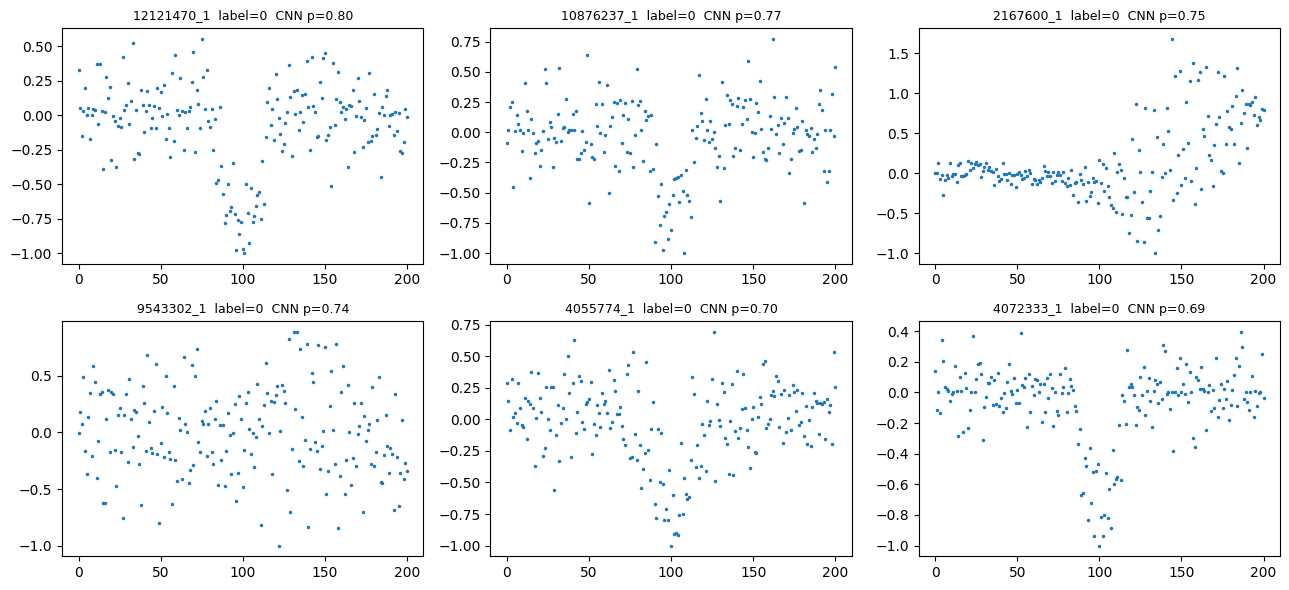

In [6]:
import matplotlib.pyplot as plt

# CNN ne jinhe planet bola (p > 0.5) lekin asli mein planet nahi
fp = np.where((p > 0.5) & (Yt == 0))[0]
print("false positives:", len(fp), "| total not-planets:", int((Yt == 0).sum()))

show = fp[np.argsort(-p[fp])][:6]   # sabse confident 6 galtiyan
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a, i in zip(ax.ravel(), show):
    a.plot(Lt[i, 0].numpy(), ".", markersize=3)
    a.set_title(f"{names[i][:-4]}  label={tdata[i][2]}  CNN p={p[i]:.2f}", fontsize=9)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/exoplanet/false_positives.png", dpi=150)
plt.show()

In [7]:
!pip install -q lightkurve
import lightkurve as lk
import matplotlib.pyplot as plt

def load_lc(kepid):
    s = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
    return s.download_all().stitch().remove_nans()

def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, d

_IncompleteInputError: incomplete input (221863866.py, line 19)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


       tce_plnt_num  tce_period  tce_time0bk  tce_duration av_training_set
17694             1     331.603       140.48         14.49              PC


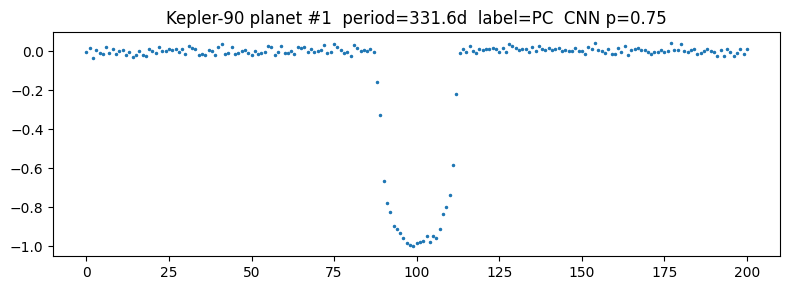

In [8]:
!pip install -q lightkurve
import lightkurve as lk
import matplotlib.pyplot as plt

def load_lc(kepid):
    s = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", cadence="long")
    return s.download_all().stitch().remove_nans()

def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1
    out = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    out[np.isnan(out)] = np.nanmedian(out)
    return out

def make_views(lc, period, t0, duration_hr):
    dur = duration_hr / 24
    mask = lc.create_transit_mask(period=period, transit_time=t0, duration=2 * dur)
    flat = lc.flatten(window_length=401, mask=mask)
    t, f = flat.time.value, flat.flux.value
    phase = (t - t0 + period / 2) % period - period / 2
    glob = binned(phase, f, -period / 2, period / 2, 2001)
    loc = binned(phase, f, -4 * dur, 4 * dur, 201)
    norm = lambda v: (v - np.median(v)) / abs((v - np.median(v)).min())
    return norm(glob), norm(loc)

lc90 = load_lc(11442793)
rows = tce[tce.kepid == 11442793][["tce_plnt_num", "tce_period", "tce_time0bk", "tce_duration", "av_training_set"]]
print(rows)

fig, ax = plt.subplots(len(rows), 1, figsize=(8, 3 * len(rows)))
ax = np.atleast_1d(ax)
for a, (_, r) in zip(ax, rows.iterrows()):
    g, l = make_views(lc90, r.tce_period, r.tce_time0bk, r.tce_duration)
    with torch.no_grad():
        pr = torch.sigmoid(net(torch.tensor(g, dtype=torch.float32)[None, None],
                               torch.tensor(l, dtype=torch.float32)[None, None])).item()
    a.plot(l, ".", markersize=3)
    a.set_title(f"Kepler-90 planet #{int(r.tce_plnt_num)}  period={r.tce_period:.1f}d  label={r.av_training_set}  CNN p={pr:.2f}")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/exoplanet/kepler90.png", dpi=150)
plt.show()